<a href="https://colab.research.google.com/github/mshitie/Dual-Brach/blob/main/quantitative%20XAI%20evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VGG16 + Quantitative XAI on COVID-19 Radiography Dataset
Classes: COVID, Lung_Opacity, Normal, Viral Pneumonia
XAI methods: Grad-CAM, Integrated Gradients (+ Random-map baseline for sanity)
Quantitative metrics:
  Faithfulness : Deletion AUC (lower = better), Insertion AUC (higher = better),
                 Average Drop % (lower = better), Increase in Confidence % (higher = better)
  Localization : Lung-mask energy, rank accuracy, pointing game, IoU (uses dataset masks)
  Stability    : Spearman correlation of maps under small Gaussian noise

In [1]:
! pip install -q kaggle

In [2]:
! cp kaggle.json ~/.kaggle/
#!cp /content/drive/MyDrive/computer_vision/kaggle.json ~/.kaggle/kaggle.json # if you upload from gdrive

cp: cannot stat 'kaggle.json': No such file or directory


In [3]:
! chmod 600 ~/.kaggle/kaggle.json

chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [4]:
import os
os.environ['KAGGLE_CONFIG_DIR']= '/content'

In [5]:
!kaggle datasets download -d tawsifurrahman/covid19-radiography-database
!unzip -q covid19-radiography-database.zip -d covid19

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
100% 778M/778M [00:08<00:00, 91.7MB/s]



In [6]:
import os, glob, random, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, auc
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# from google.colab import drive; drive.mount('/content/drive')
DATA_DIR = "/content/covid19/COVID-19_Radiography_Dataset"   # <-- change to your path
CLASSES = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
IMG_SIZE, BATCH = 224, 32
MAX_PER_CLASS = None      # e.g. 1500 to balance classes / speed up training
N_EVAL_PER_CLASS = 25     # images per class used for the XAI evaluation
print("GPU:", tf.config.list_physical_devices("GPU"))


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [14]:
rows = []
for c in CLASSES:
    for p in glob.glob(os.path.join(DATA_DIR, c, "images", "*.png")):
        m = os.path.join(os.path.dirname(os.path.dirname(p)), "masks", os.path.basename(p))
        rows.append({"path": p, "mask_path": m, "label": c})
df = pd.DataFrame(rows)

if MAX_PER_CLASS:
    df = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED)
                    for _, g in df.groupby("label")]).reset_index(drop=True)

label2idx = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["label"].map(label2idx)
print(df["label"].value_counts())

train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.y, random_state=SEED)
print(len(train_df), len(val_df), len(test_df))


label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64
14815 3175 3175


In [8]:
AUTOTUNE = tf.data.AUTOTUNE
aug = tf.keras.Sequential([layers.RandomRotation(0.04),
                           layers.RandomZoom(0.1),
                           layers.RandomTranslation(0.05, 0.05)])   # no horizontal flip (heart side matters)

def load_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE))               # float32, 0-255

def make_ds(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(lambda p, y: (load_img(p), y), num_parallel_calls=AUTOTUNE).batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)


In [9]:
base = VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
out = layers.Dense(len(CLASSES), activation="softmax")(x)
model = models.Model(base.input, out, name="vgg16_cxr")

def set_trainable(unfreeze_block5):
    for l in model.layers:
        if l.name.startswith("block"):
            l.trainable = unfreeze_block5 and l.name.startswith("block5")

def compile_model(lr):
    model.compile(optimizer=optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_df.y.values)
cw = {i: w for i, w in enumerate(cw)}
cbs = [callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
       callbacks.ReduceLROnPlateau(factor=0.3, patience=2, monitor="val_loss")]

# Phase 1: train the head only
set_trainable(False); compile_model(1e-3)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=cw, callbacks=cbs)
# Phase 2: fine-tune block5
set_trainable(True); compile_model(1e-5)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=cw, callbacks=cbs)
model.save("vgg16_covid_cxr.keras")


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 237s 491ms/step - accuracy: 0.7004 - loss: 0.7480 - val_accuracy: 0.8161 - val_loss: 0.4945 - learning_rate: 0.0010
Epoch 2/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 233s 446ms/step - accuracy: 0.7749 - loss: 0.4938 - val_accuracy: 0.8101 - val_loss: 0.5119 - learning_rate: 0.0010
Epoch 3/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 219s 472ms/step - accuracy: 0.7947 - loss: 0.4459 - val_accuracy: 0.8567 - val_loss: 0.4137 - learning_rate: 0.0010
Epoch 4/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 260s 467ms/step - accuracy: 0.8030 - loss: 0.4328 - val_accuracy: 0.8268 - val_loss: 0.4545 - learning_rate: 0.0010
Epoch 5/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 208s 447ms/step - accuracy: 0.8173 - loss: 0.3977 - val_accuracy: 0.8545 - val_loss: 0.3936 - learning_rate: 0.0010
Epoch 6/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 211s 452ms/step - accuracy: 0.8173 - loss: 0.3951 - val_accuracy: 0.8510 - val_loss: 0.4159 - learning_rate: 0.0010
Epoch 7/10
46

100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 145ms/step
                 precision    recall  f1-score   support

          COVID     0.9468    0.9520    0.9494       542
   Lung_Opacity     0.9150    0.8836    0.8990       902
         Normal     0.9256    0.9444    0.9349      1529
Viral Pneumonia     0.9799    0.9653    0.9726       202

       accuracy                         0.9298      3175
      macro avg     0.9418    0.9363    0.9390      3175
   weighted avg     0.9297    0.9298    0.9296      3175

Macro OvR AUC: 0.9899410870080617


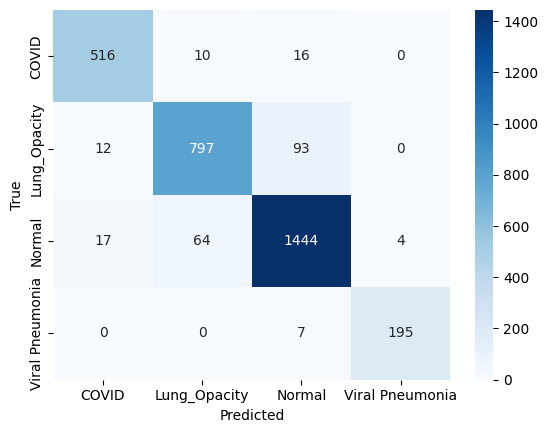

In [10]:
y_prob = model.predict(test_ds)
y_pred = y_prob.argmax(1)
y_true = test_df.y.values
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("Macro OvR AUC:", roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()


In [11]:
LAST_CONV = "block5_conv3"
grad_model = models.Model(model.input, [model.get_layer(LAST_CONV).output, model.output])

def minmax(a):
    a = a - a.min()
    return a / (a.max() + 1e-8)

def gradcam(x, cls=None):
    """x: (1,224,224,3) preprocessed. Returns map in [0,1] (224x224)."""
    if cls is None:
        cls = int(np.argmax(model(x, training=False)[0]))
    with tf.GradientTape() as tape:
        conv, preds = grad_model(x, training=False)
        score = preds[:, cls]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0].numpy()
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    return minmax(cam)

def integrated_gradients(x, cls=None, steps=32):
    if cls is None:
        cls = int(np.argmax(model(x, training=False)[0]))
    x = tf.convert_to_tensor(x, tf.float32)
    baseline = tf.zeros_like(x)                      # = mean ImageNet pixel after preprocessing
    alphas = tf.linspace(0.0, 1.0, steps + 1)[:, None, None, None]
    inter = baseline + alphas * (x - baseline)
    with tf.GradientTape() as tape:
        tape.watch(inter)
        p = model(inter, training=False)[:, cls]
    g = tape.gradient(p, inter)
    avg = tf.reduce_mean((g[:-1] + g[1:]) / 2.0, axis=0, keepdims=True)   # trapezoid rule
    ig = ((x - baseline) * avg)[0]
    attr = tf.reduce_sum(tf.abs(ig), axis=-1).numpy()
    attr = cv2.GaussianBlur(attr, (0, 0), 2)
    return minmax(attr)

def random_map(x, cls=None):
    return minmax(cv2.GaussianBlur(np.random.rand(IMG_SIZE, IMG_SIZE).astype("float32"), (0, 0), 15))

EXPLAINERS = {"Grad-CAM": gradcam, "Integrated Gradients": integrated_gradients,
              "Random (baseline)": random_map}


In [12]:
def predict_cls_prob(imgs, cls):
    return model.predict(imgs, batch_size=32, verbose=0)[:, cls]

def deletion_insertion(x, cam, cls, steps=20):
    """x: (224,224,3) preprocessed. Returns (deletion_auc, insertion_auc, curves)."""
    order = np.argsort(-cam.ravel())
    n = cam.size
    blur = cv2.GaussianBlur(x, (0, 0), 10)
    fr = np.linspace(0, 1, steps + 1)
    del_imgs, ins_imgs = [], []
    for f in fr:
        mask = np.zeros(n, bool); mask[order[:int(f * n)]] = True
        mask = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
        del_imgs.append(np.where(mask, 0.0, x))      # remove most relevant pixels -> mean gray
        ins_imgs.append(np.where(mask, x, blur))     # reveal most relevant pixels on blurred image
    pd_ = predict_cls_prob(np.stack(del_imgs), cls)
    pi_ = predict_cls_prob(np.stack(ins_imgs), cls)
    return auc(fr, pd_), auc(fr, pi_), (fr, pd_, pi_)

def drop_and_increase(x, cam, cls):
    """Average Drop & Increase-in-Confidence: explanation-masked image vs. original."""
    y = predict_cls_prob(x[None], cls)[0]
    o = predict_cls_prob((x * cam[..., None])[None], cls)[0]
    return max(0.0, y - o) / (y + 1e-8) * 100, float(o > y) * 100

def lung_mask(path):
    m = cv2.imread(path, 0)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return (m > 127).astype(np.float32)

def localization(cam, mask):
    energy = (cam * mask).sum() / (cam.sum() + 1e-8)                      # relevance mass inside lungs
    K = int(mask.sum())
    top = np.argsort(-cam.ravel())[:K]
    rank_acc = mask.ravel()[top].mean()                                   # top-K pixels inside lungs
    pointing = float(mask.ravel()[np.argmax(cam.ravel())] > 0)            # max point inside lungs
    binm = cam > 0.5
    iou = (binm & (mask > 0)).sum() / ((binm | (mask > 0)).sum() + 1e-8)
    return energy, rank_acc, pointing, iou

def stability(explainer, x, cls, base_cam, n=3, sigma=5.0):
    """Mean Spearman correlation between the map and maps from noisy inputs
    (noise in preprocessed space, sigma~5 on a 0-255 scale)."""
    rs = []
    for _ in range(n):
        xn = x + np.random.normal(0, sigma, x.shape).astype("float32")
        if int(np.argmax(model(xn[None], training=False)[0])) != cls:
            continue
        c2 = explainer(xn[None], cls)
        rs.append(spearmanr(base_cam.ravel(), c2.ravel())[0])
    return np.nanmean(rs) if rs else np.nan


In [15]:
eval_df = pd.concat([g.sample(min(len(g), N_EVAL_PER_CLASS), random_state=SEED)
                     for _, g in test_df.groupby("label")]).reset_index(drop=True)

records, curves = [], {k: {"del": [], "ins": []} for k in EXPLAINERS}
for i, r in eval_df.iterrows():
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    mask = lung_mask(r["mask_path"])
    for name, fn in EXPLAINERS.items():
        cam = fn(x[None], cls)
        d_auc, i_auc, (fr, pdel, pins) = deletion_insertion(x, cam, cls)
        avg_drop, inc_conf = drop_and_increase(x, cam, cls)
        energy, rank_acc, pointing, iou = localization(cam, mask)
        stab = stability(fn, x, cls, cam)
        curves[name]["del"].append(pdel); curves[name]["ins"].append(pins)
        records.append(dict(method=name, true=r.label, pred=CLASSES[cls], correct=cls == r.y,
                            deletion_auc=d_auc, insertion_auc=i_auc,
                            avg_drop=avg_drop, inc_conf=inc_conf,
                            lung_energy=energy, rank_acc=rank_acc, pointing=pointing, iou=iou,
                            stability=stab, lung_area_frac=mask.mean()))
    if (i + 1) % 10 == 0:
        print(f"{i+1}/{len(eval_df)} images done")

res = pd.DataFrame(records)
res.to_csv("xai_quantitative_per_image.csv", index=False)


10/100 images done
20/100 images done
30/100 images done
40/100 images done
50/100 images done
60/100 images done
70/100 images done
80/100 images done
90/100 images done
100/100 images done


In [16]:
metric_cols = ["deletion_auc", "insertion_auc", "avg_drop", "inc_conf",
               "lung_energy", "rank_acc", "pointing", "iou", "stability"]
summary = res.groupby("method")[metric_cols].agg(["mean", "std"]).round(4)
print("=== Overall (mean, std) ===")
print(summary.T)
summary.to_csv("xai_quantitative_summary.csv")

print("\n=== Per true class (mean) ===")
per_class = res.groupby(["method", "true"])[metric_cols].mean().round(4)
print(per_class)
per_class.to_csv("xai_quantitative_per_class.csv")

print("\nChance level for lung_energy / rank_acc / pointing ~ mean lung area fraction:",
      round(res.lung_area_frac.mean(), 3))
print("Interpretation: deletion_auc & avg_drop lower = better | insertion_auc, inc_conf, "
      "lung_energy, rank_acc, pointing, iou, stability higher = better.")


=== Overall (mean, std) ===
method               Grad-CAM  Integrated Gradients  Random (baseline)
deletion_auc  mean   0.292700              0.399000           0.407500
              std    0.266500              0.245400           0.282000
insertion_auc mean   0.718000              0.554300           0.482700
              std    0.223700              0.256700           0.271800
avg_drop      mean  59.710800             69.852402          26.675600
              std   43.794998             38.849400          35.053699
inc_conf      mean   6.000000              4.000000           8.000000
              std   23.868300             19.694600          27.266000
lung_energy   mean   0.302500              0.138200           0.229200
              std    0.139100              0.081500           0.060700
rank_acc      mean   0.332200              0.091200           0.210300
              std    0.171900              0.126400           0.106300
pointing      mean   0.270000              0.0300

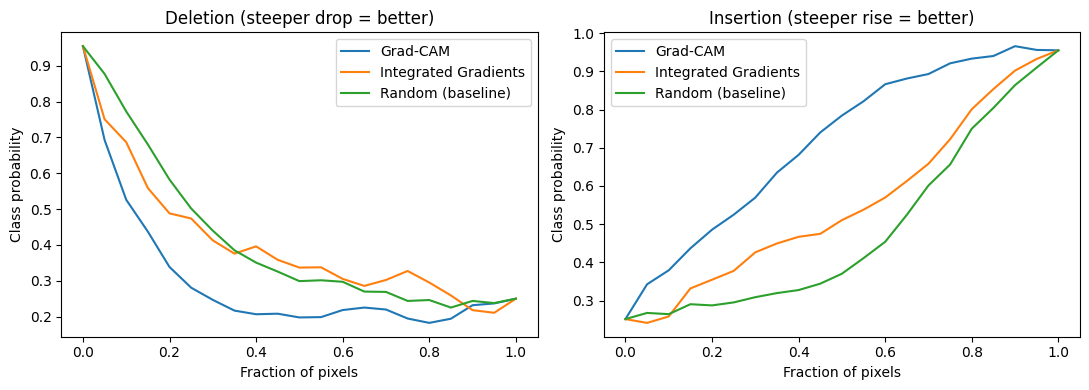

In [17]:
fr = np.linspace(0, 1, 21)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in EXPLAINERS:
    ax[0].plot(fr, np.mean(curves[name]["del"], 0), label=name)
    ax[1].plot(fr, np.mean(curves[name]["ins"], 0), label=name)
ax[0].set_title("Deletion (steeper drop = better)"); ax[1].set_title("Insertion (steeper rise = better)")
for a in ax:
    a.set_xlabel("Fraction of pixels"); a.set_ylabel("Class probability"); a.legend()
plt.tight_layout(); plt.savefig("deletion_insertion_curves.png", dpi=200); plt.show()


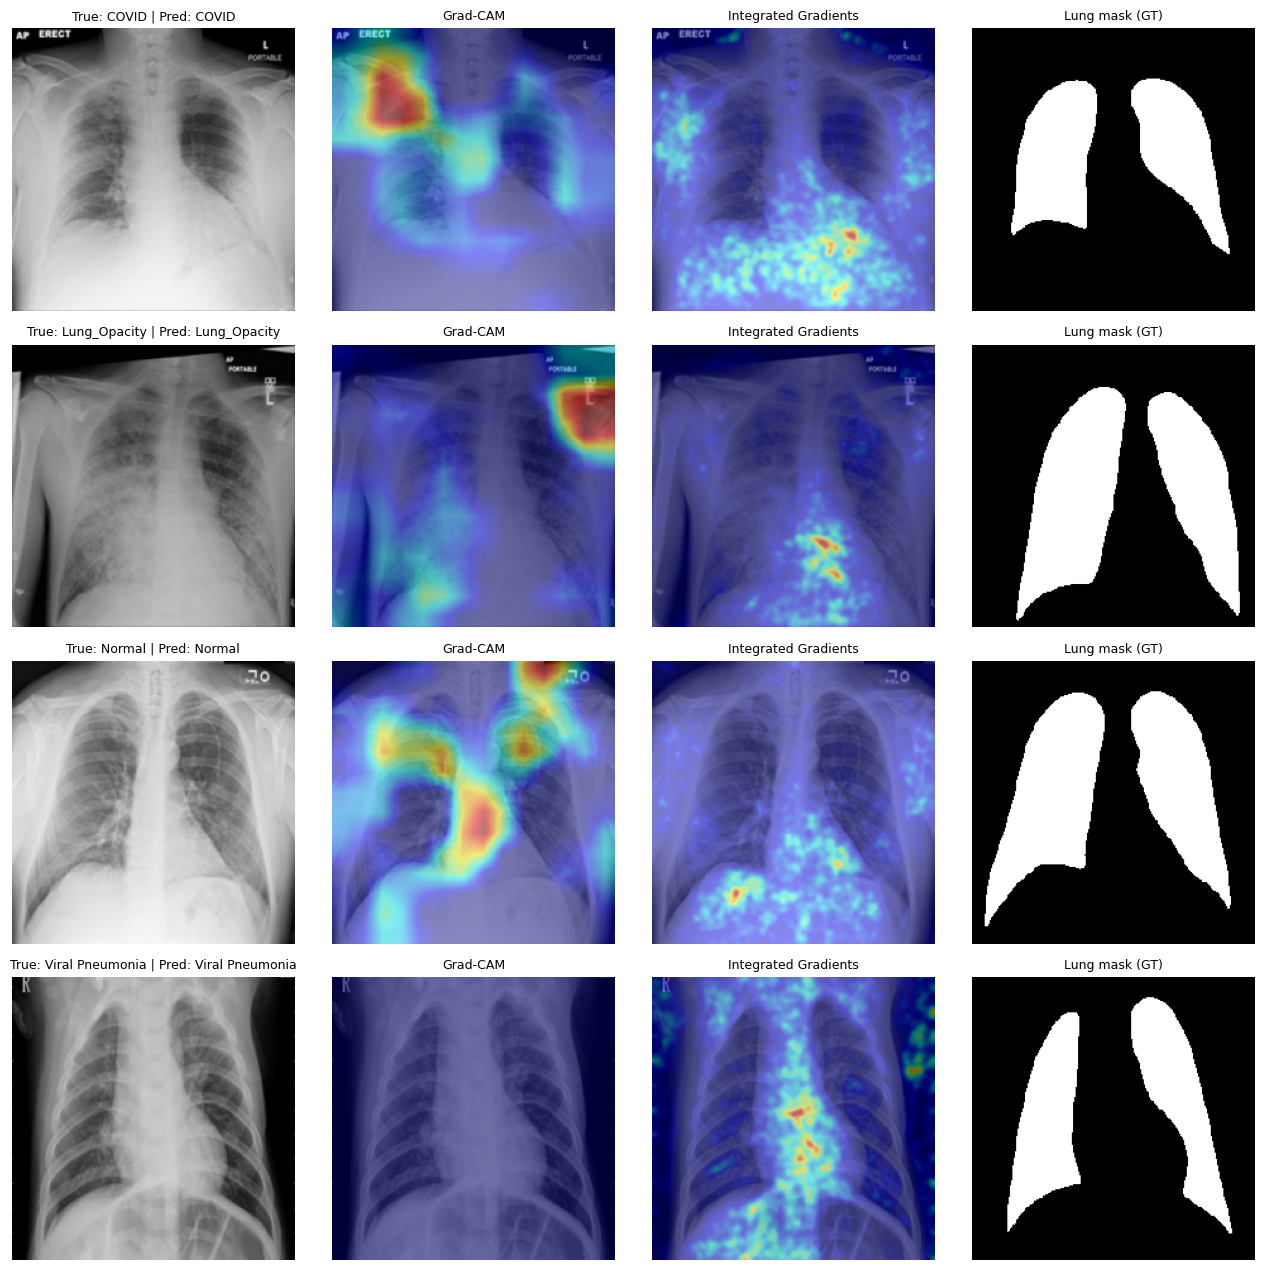

In [19]:
fig, axs = plt.subplots(len(CLASSES), 4, figsize=(13, 3.2 * len(CLASSES)))
for row, c in enumerate(CLASSES):
    r = eval_df[eval_df["label"] == c].iloc[0]
    raw = load_img(r["path"]).numpy().astype("uint8")
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    gc, ig = gradcam(x[None], cls), integrated_gradients(x[None], cls)
    def overlay(m):
        heat = cv2.applyColorMap((m * 255).astype("uint8"), cv2.COLORMAP_JET)[..., ::-1]
        return (0.55 * raw + 0.45 * heat).astype("uint8")
    for a, im, t in zip(axs[row], [raw, overlay(gc), overlay(ig), lung_mask(r["mask_path"])],
                        [f"True: {c} | Pred: {CLASSES[cls]}", "Grad-CAM", "Integrated Gradients", "Lung mask (GT)"]):
        a.imshow(im, cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig("xai_qualitative.png", dpi=200); plt.show()